In [1]:
import cupy as cp
import pandas as pd
import seaborn as sns
import cuml
import matplotlib.pyplot as plt
import numpy as np
from xgboost import XGBRegressor
from cuml.ensemble import RandomForestRegressor
from hyperopt import hp, fmin, tpe, Trials, STATUS_OK
from cuml.metrics import r2_score as cuml_r2_score  # GPU Metrics
from cuml.model_selection import train_test_split as cuml_split
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import shap

/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/xgboost/_c_api.py:180: FutureWarning: `rapids-xgboost` will no longer be published in the `rapidsai` conda channel with the 26.10 release. Please use the `xgboost` package from `conda-forge`, or the `xgboost` wheel from the Python Package Index (PyPI). Consult https://docs.rapids.ai/notices/rsn0062/ for more details.
  warnings.warn(
/home/aashr/miniforge3/envs/rapids-26.08/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data = pd.read_csv("/home/aashr/-/Py/Minor_Spec/Papers/1-s2.0-S2666016424001440-mmc1.csv")
data

,ID,Type of MB,Types of contaminants,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,1,polypropylene (PP),2-(2-Butoxyethoxy)ethanol,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,2,polypropylene (PP),Caprolactam,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,3,polypropylene (PP),Creatine,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,4,polypropylene (PP),Formaldehyde,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,5,polypropylene (PP),Isopropanol,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,1903,Poly(p-phenylene oxide) (PPO),Indomethacin,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,1904,Poly(p-phenylene oxide) (PPO),Cephalexin hydrate,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,1905,Poly(p-phenylene oxide) (PPO),Diltiazem,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,1906,Poly(p-phenylene oxide) (PPO),Erythromycin,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [3]:
# data = data[[
#     "Compound Mw (g/mol)",
#     "Compound Kow",
#     "Pressure (kPa)",
#     "Measurement time (min)",
#     "Initial concentration of compound (mg/L)",
#     "min projection (Å)",
#     "max projection (Å)",
#     "MB MWCO (Da)",
#     "MB contact angle (°)",
#     "MB zeta potential",
#     "Compound charge",
#     "pH",
#     "removal rate (%)"
# ]].copy()

# data = data.apply(pd.to_numeric, errors="coerce").dropna().reset_index(drop=True)
# data

In [4]:

# df = pd.get_dummies(data, columns=["Type of MB"])
# df = pd.get_dummies(df, columns=[ "Types of contaminants"])
# df = df.drop(columns=["ID"])

df = data.drop(columns=["ID", "Type of MB", "Types of contaminants"]) 
df

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm),removal rate (%)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512,81.5900
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396,82.8500
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382,96.6500
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221,3.3500
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315,65.2700
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669,97.0719
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550,95.2613
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722,98.3872
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798,94.7621


In [5]:
# df = df.dropna()

In [6]:
len(df.columns)

15

In [7]:
# Paper-style 6-feature setup: keep the same exact variables used in the study
# and avoid any invalid log transform on negative Kow values.
Y = df["removal rate (%)"].astype(float)
X = df.drop(columns=["removal rate (%)"]).copy()

# Convert all features to numeric and keep only valid rows
X = X.apply(pd.to_numeric, errors="coerce")
Y = Y.loc[X.index]

print(X.head())
print("Shape:", X.shape)

    pH  Compound Mw (g/mol)  Compound charge  Compound Kow  \
0  7.0              162.229              0.0         0.711   
1  7.0              113.160              0.0         0.310   
2  7.0              131.135              0.0        -2.864   
3  7.0               30.026              0.0        -0.467   
4  7.0               60.096              0.0         0.255   

   min projection (Å)  max projection (Å)  MB MWCO (Da)  MB contact angle (°)  \
0                3.25                8.08           150                  50.0   
1                3.92                4.01           150                  50.0   
2                3.35                4.36           150                  50.0   
3                2.08                2.34           150                  50.0   
4                2.95                3.36           150                  50.0   

   MB zeta potential  Total charge  Pressure (kPa)  Measurement time (min)  \
0               -1.0           0.0           800.0            

In [8]:
# Keep the raw Compound Kow values. The paper dataset contains negative Kow values,
# so log10 would produce invalid values and distort the model.
X["Compound Kow"] = pd.to_numeric(X["Compound Kow"], errors="coerce")
# X = X.dropna()
Y = Y.loc[X.index]

print("Negative Kow count:", int((X["Compound Kow"] < 0).sum()))
print("Final X shape:", X.shape)

Negative Kow count: 319
Final X shape: (1906, 14)


In [9]:
X

,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798


In [10]:
# view = data.drop(columns=["Type of MB", "Types of contaminants"])
print(df.min())
print(df.max())


pH                                            2.20000
Compound Mw (g/mol)                          30.02600
Compound charge                              -2.00000
Compound Kow                                 -6.30000
min projection (Å)                            2.08000
max projection (Å)                            2.34000
MB MWCO (Da)                                 65.00000
MB contact angle (°)                         14.40000
MB zeta potential                            -1.00000
Total charge                                 -1.99610
Pressure (kPa)                              240.00000
Measurement time (min)                       10.00000
Initial concentration of compound (mg/L)      0.00072
compound size (nm)                            0.22100
removal rate (%)                              0.00000
dtype: float64
pH                                            11.0000
Compound Mw (g/mol)                          837.0580
Compound charge                                1.8281
Compound Kow 

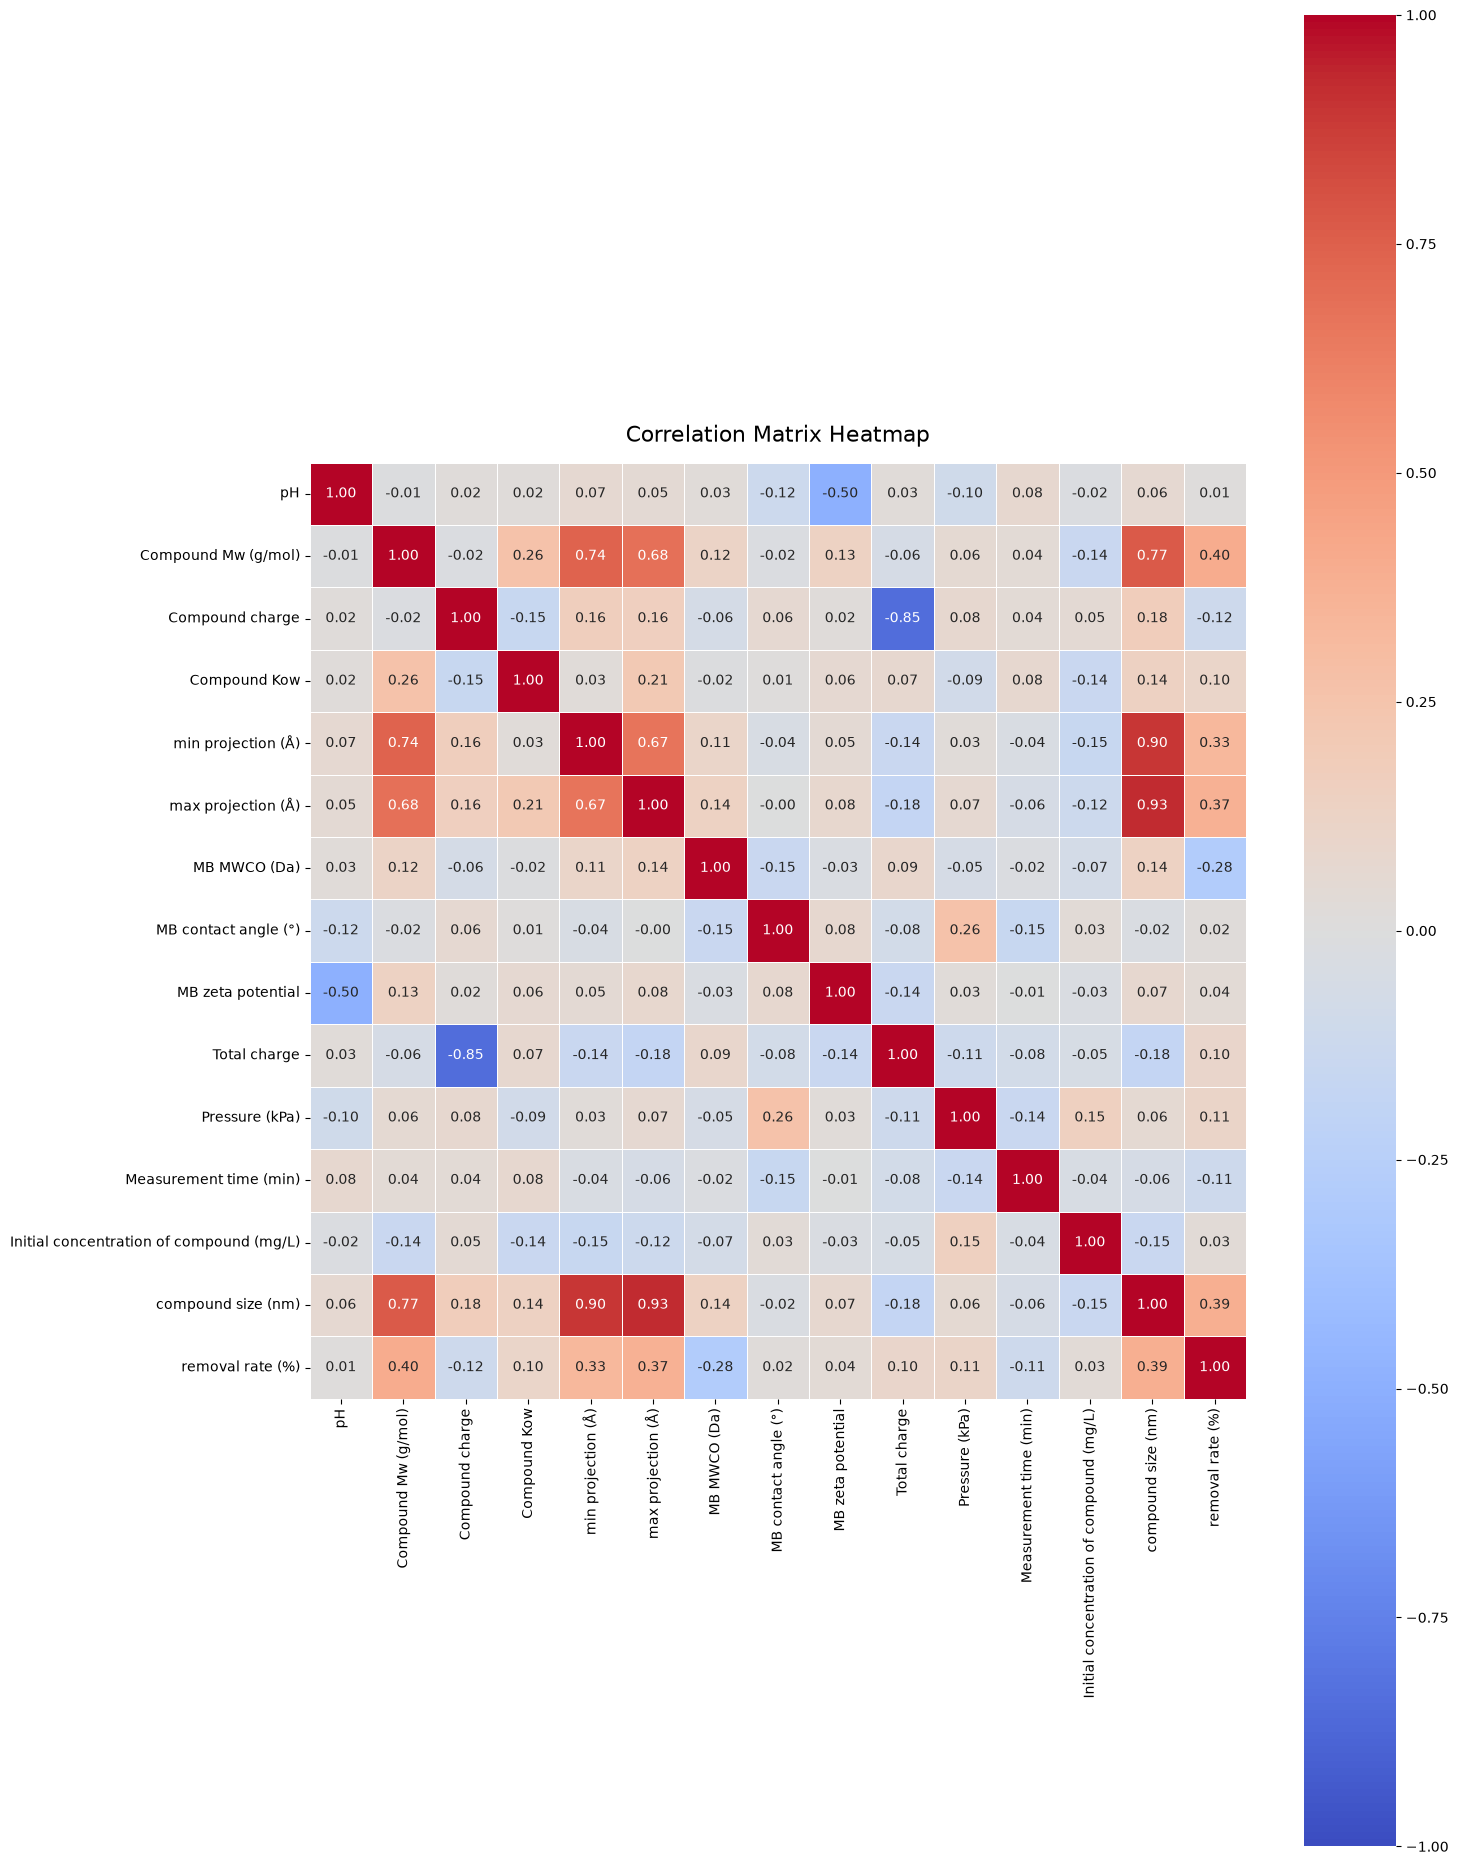

In [11]:
df_num = df.select_dtypes(include=[np.number])
corr = df_num.corr()
# 3. Create a clean heatmap
plt.figure(figsize=(15, 19))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)
plt.title("Correlation Matrix Heatmap", fontsize=16, pad=15)
plt.tight_layout()
plt.show()

In [12]:
# from scipy import stats
# import numpy as np

# z = np.abs(stats.zscore(X))
# mask = (z < 3).all(axis=1)

# X = X[mask]
# Y = Y[mask]
# X

In [13]:
X = X.replace([np.inf, -np.inf], np.nan)
valid_idx = X.dropna().index
X = X.loc[valid_idx]
Y = Y.loc[valid_idx]

In [14]:
print(X.shape)
X

(1906, 14)


,pH,Compound Mw (g/mol),Compound charge,Compound Kow,min projection (Å),max projection (Å),MB MWCO (Da),MB contact angle (°),MB zeta potential,Total charge,Pressure (kPa),Measurement time (min),Initial concentration of compound (mg/L),compound size (nm)
0,7.0,162.229,0.0000,0.711,3.25,8.08,150,50.0,-1.0,0.0000,800.0,10.0,0.16223,0.512
1,7.0,113.160,0.0000,0.310,3.92,4.01,150,50.0,-1.0,0.0000,800.0,10.0,0.11316,0.396
2,7.0,131.135,0.0000,-2.864,3.35,4.36,150,50.0,-1.0,0.0000,800.0,10.0,0.13114,0.382
3,7.0,30.026,0.0000,-0.467,2.08,2.34,150,50.0,-1.0,0.0000,800.0,10.0,0.03003,0.221
4,7.0,60.096,0.0000,0.255,2.95,3.36,150,50.0,-1.0,0.0000,800.0,10.0,0.06010,0.315
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1901,7.0,357.790,-1.0000,3.530,5.24,8.54,200,22.6,-1.0,1.0000,500.0,1440.0,0.02000,0.669
1902,7.0,347.390,-0.3711,-2.142,4.74,6.38,200,22.6,-1.0,0.3711,500.0,1440.0,0.02000,0.550
1903,7.0,414.520,0.9374,2.727,6.13,8.50,200,22.6,-1.0,-0.9374,500.0,1440.0,0.02000,0.722
1904,7.0,733.937,1.0000,2.596,6.83,9.32,200,22.6,-1.0,-1.0000,500.0,1440.0,0.02000,0.798


In [19]:
feature_names = X.columns.tolist()

X_train, X_test, y_train, y_test = cuml_split(
    X, Y, test_size=0.2, random_state=42
)

X_train = cp.asarray(X_train, dtype=cp.float32)
y_train = cp.asarray(y_train, dtype=cp.float32)
X_test = cp.asarray(X_test, dtype=cp.float32)
y_test = cp.asarray(y_test, dtype=cp.float32)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape) 

Train shape: (1524, 14)
Test shape: (382, 14)


In [16]:
param_space_rf = {
    "n_estimators": hp.quniform("n_estimators", 100, 400, 50),
    "max_depth": hp.quniform("max_depth", 6, 14, 2),
    "min_samples_split": hp.choice("min_samples_split", [2, 5, 10]),
    "min_samples_leaf": hp.choice("min_samples_leaf", [1, 2, 4]),
    "max_features": hp.uniform("max_features", 0.4, 0.9), # Fraction of features to consider
    "bootstrap": hp.choice("bootstrap", [True, False])
}

def objective_rf(params):
    # Cast types properly for cuML
    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    
    # K-Fold split manually since sklearn's cross_val_score will break on CuPy arrays
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    r2_scores = []
    
    for train_idx, val_idx in kf.split(np.arange(X_train.shape[0])): # .get() moves indexes to CPU for KFold splitting
        # Slice CuPy arrays cleanly on the GPU
        X_tr = X_train[train_idx]
        X_val = X_train[val_idx]

        y_tr = y_train[train_idx]
        y_val = y_train[val_idx]
        
        # Initialize cuML Random Forest (n_jobs handles CPU fallback, omit it for true GPU usage)
        model = RandomForestRegressor(
            random_state=42,
            n_streams=4,
            **params
        )
        model.fit(X_tr, y_tr)
        
        # Predict and score entirely on the GPU
        preds = model.predict(X_val)
        r2 = cuml_r2_score(y_val, preds)
        r2_scores.append(r2)
        
    mean_r2 = np.mean(r2_scores)
    return {'loss': -mean_r2, 'status': STATUS_OK}

In [17]:
print("Starting Hyperopt optimization for cuML Random Forest...")
trials_rf = Trials()
best_params_rf = fmin(
    fn=objective_rf,
    space=param_space_rf,
    algo=tpe.suggest,
    max_evals=50,  # Adjust iterations based on your time constraints
    trials=trials_rf
)

# Fix Hyperopt type mappings for index-based hp.choice parameters
bootstrap_options = [True, False]
min_samples_split_options = [2, 5, 10]
min_samples_leaf_options = [1, 2, 4]

best_params_rf["n_estimators"] = int(best_params_rf["n_estimators"])
best_params_rf["max_depth"] = int(best_params_rf["max_depth"])
best_params_rf["bootstrap"] = bootstrap_options[best_params_rf["bootstrap"]]
best_params_rf["min_samples_split"] = min_samples_split_options[best_params_rf["min_samples_split"]]
best_params_rf["min_samples_leaf"] = min_samples_leaf_options[best_params_rf["min_samples_leaf"]]

print("\n--- Optimization Complete ---")
print("Best RF Parameters:", best_params_rf)

Starting Hyperopt optimization for cuML Random Forest...
100%|██████████| 50/50 [07:33<00:00,  9.07s/trial, best loss: -0.7668652415275574]

--- Optimization Complete ---
Best RF Parameters: {'bootstrap': False, 'max_depth': 14, 'max_features': np.float64(0.4962664366794389), 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [20]:
final_rf_model = RandomForestRegressor(random_state=42, n_streams=4, **best_params_rf)
final_rf_model.fit(X_train, y_train)

# Predict on GPU
rf_pred = final_rf_model.predict(X_test)

# Pull variables back to CPU (.get()) just for standard Scikit-Learn evaluation metrics
y_test_cpu = y_test.get()
rf_pred_cpu = rf_pred.get()

rf_mse = mean_squared_error(y_test_cpu, rf_pred_cpu)
rf_rmse = np.sqrt(rf_mse)
rf_mae = mean_absolute_error(y_test_cpu, rf_pred_cpu)
rf_r2 = r2_score(y_test_cpu, rf_pred_cpu)
    
print("\nRandom Forest Final Test Metrics:")
print(f"MSE: {rf_mse:.4f}")
print(f"RMSE: {rf_rmse:.4f}")
print(f"MAE: {rf_mae:.4f}")
print(f"R² Score: {rf_r2:.4f}")


Random Forest Final Test Metrics:
MSE: 169.3859
RMSE: 13.0148
MAE: 7.4928
R² Score: 0.7782


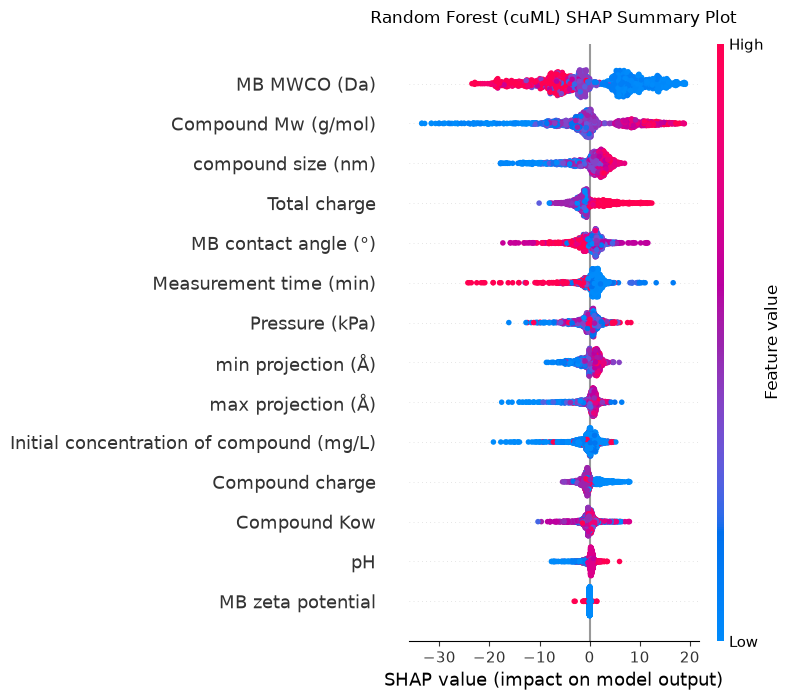

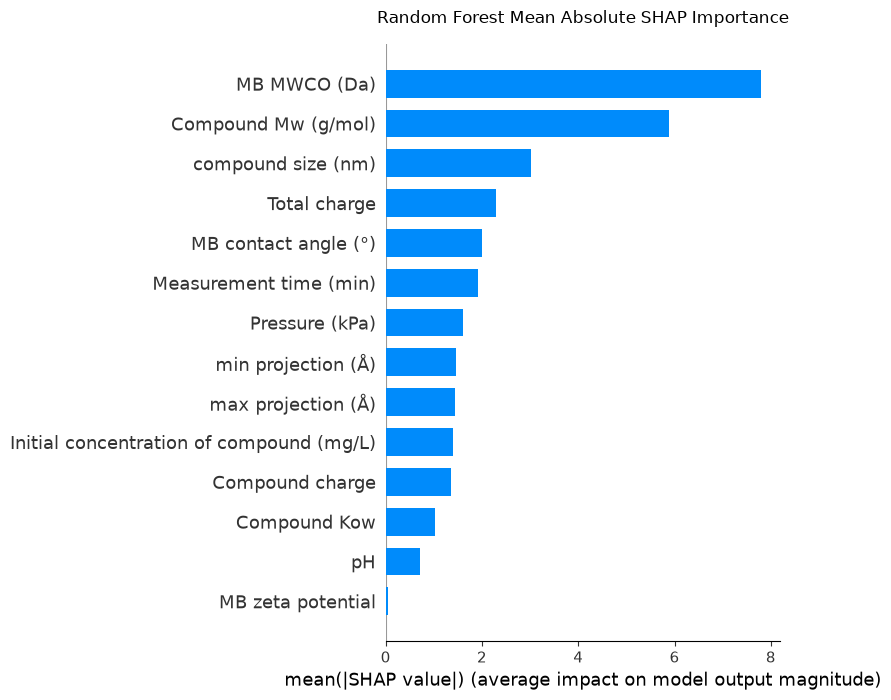

RF SHAP Top-6:
['MB MWCO (Da)', 'Compound Mw (g/mol)', 'compound size (nm)', 'Total charge', 'MB contact angle (°)', 'Measurement time (min)']


In [21]:
from cuml.explainer import TreeExplainer as cuMLTreeExplainer

rf_explainer = cuMLTreeExplainer(model=final_rf_model)
# 2. Compute SHAP values on GPU (using X_train or X_test CuPy arrays)
rf_shap_values = rf_explainer.shap_values(X_train)
# 3. Pull values back to CPU for SHAP visualization plots
rf_shap_values_cpu = rf_shap_values.get()
X_train_cpu = X_train.get()
# Summary Beeswarm Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    rf_shap_values_cpu, 
    X_train_cpu, 
    feature_names=feature_names,
    show=False
)
plt.title("Random Forest (cuML) SHAP Summary Plot", pad=15)
plt.tight_layout()
plt.show()
# Mean Absolute SHAP Bar Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(
    rf_shap_values_cpu, 
    X_train_cpu, 
    feature_names=feature_names, 
    plot_type="bar",
    show=False
)
plt.title("Random Forest Mean Absolute SHAP Importance", pad=15)
plt.tight_layout()
plt.show()
# Feature Importance DataFrame
rf_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": np.abs(rf_shap_values_cpu).mean(axis=0)
}).sort_values(by="importance", ascending=False)

rf_top6_features = (
    rf_importance
    .head(6)["feature"]
    .tolist()
)

print("RF SHAP Top-6:")
print(rf_top6_features)


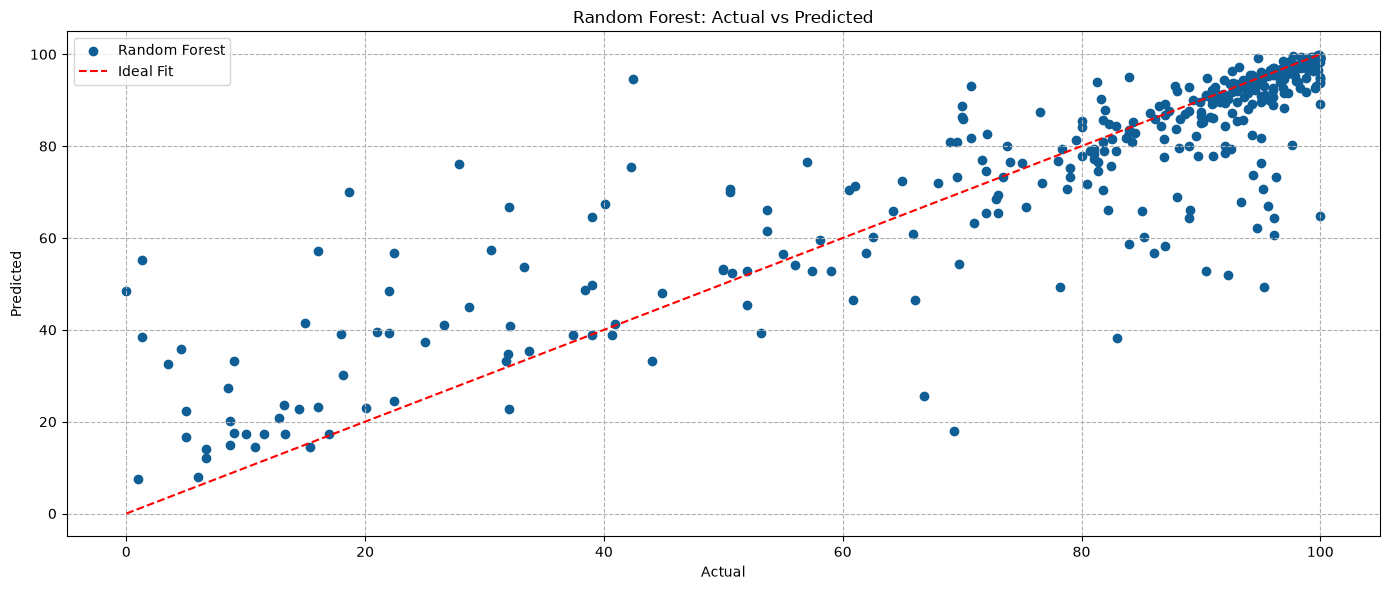

In [22]:
plt.figure(figsize=(14, 6))

plt.scatter(y_test_cpu, rf_pred_cpu, color="#105e96", label='Random Forest')
plt.plot([y_test_cpu.min(), y_test_cpu.max()], [y_test_cpu.min(), y_test_cpu.max()], 'r--', label='Ideal Fit')
plt.xlabel("Actual")
plt.ylabel("Predicted") 
plt.title("Random Forest: Actual vs Predicted")
plt.legend()
plt.grid(True, linestyle='--')

plt.tight_layout()
plt.show()
